# What Does It Take to Make a Mind?

*The Mathematics of Machine Intelligence · Chapter 1*

Turn a noisy recording into an estimate, weigh unequal voices, and ask what a partnership added.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what each source reports and how reliable it is, whether their errors are independent, what the best real alternative is, and whether a claim is a measured result, a drawn comparison or an open question. Work the weights and the comparison by hand before running any simulation, and say what was constructed.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 1, What Does It Take to Make a Mind?: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def phi(z):
    """Standard normal cumulative probability."""
    return 0.5 * (1.0 + math.erf(z / math.sqrt(2.0)))
MEANS = np.array([-1.0, 0.0, 1.0])
ATTEMPTS = ['left hip', 'neither', 'right hip']

def decoder_probabilities(x, sigma):
    """Equal starting odds and equal-spread bell curves: p_k is proportional to exp(-(x - mean_k)^2 / (2 sigma^2))."""
    weights = np.exp(-(x - MEANS) ** 2 / (2.0 * sigma ** 2))
    return weights / weights.sum()

def ideal_accuracy(sigma):
    """Chance a nearest-mean rule is right when the three means are known exactly: (4 Phi(0.5/sigma) - 1) / 3."""
    return (4.0 * phi(0.5 / sigma) - 1.0) / 3.0

def decoder_picture(x=0.75, sigma=1.0):
    p = decoder_probabilities(x, sigma)
    fig, ax = panels()
    grid = np.linspace(-3.6, 3.6, 300)
    colours = [TEAL, GREY, TERRA]
    for mean, name, colour in zip(MEANS, ATTEMPTS, colours):
        density = np.exp(-(grid - mean) ** 2 / (2 * sigma ** 2)) / (sigma * math.sqrt(2 * math.pi))
        ax[0].plot(grid, density, color=colour, linewidth=2.2, label=name)
    ax[0].axvline(x, color=NAVY, linewidth=2.2)
    ax[0].text(x - 0.1, 0.02, 'this recording', color=NAVY, fontsize=9, rotation=90, ha='right', va='bottom', bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1, 'alpha': 0.8})
    ax[0].set(xlabel='recorded value (arbitrary units)', ylabel='how common this value is', title='Each attempt leaves a noisy value')
    ax[0].legend(fontsize=9, loc='upper left')
    bars = ax[1].bar(ATTEMPTS, p, color=colours, width=0.6)
    for bar, v in zip(bars, p):
        tag(ax[1], bar.get_x() + bar.get_width() / 2, v + 0.02, sig(v), va='bottom')
    ax[1].set(ylabel='estimated probability', title='What the decoder reports', ylim=(0, 1.1))
    top = p.max()
    leaders = [name for name, v in zip(ATTEMPTS, p) if abs(v - top) < 1e-09]
    best = f"tie: {' and '.join(leaders)}" if len(leaders) > 1 else leaders[0]
    metrics = {'Probability of left hip': sig(p[0]), 'Probability of neither': sig(p[1]), 'Probability of right hip': sig(p[2]), 'Most likely attempt': best}
    if len(leaders) > 1:
        summary = f'The recording sits exactly midway between two attempts, so both get the same probability, {sig(top)}. The decoder reports a probability for each attempt, and a tie is a legitimate output, not a mistake.'
    else:
        summary = f'At recorded value {x:g} with noise {sigma:g}, the most likely attempt is {best} at probability {sig(top)}. The decoder gives a probability for each attempt and never a command.'
    exps = ', '.join((f'e^(-({x:g} - ({m:g}))^2 / {2 * sigma ** 2:g}) = {sig(w)}' for m, w in zip(MEANS, np.exp(-(x - MEANS) ** 2 / (2 * sigma ** 2)))))
    calc = f'Weights for left hip, neither, right hip: {exps}. Each probability is its weight divided by the total {sig(np.exp(-(x - MEANS) ** 2 / (2 * sigma ** 2)).sum())}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CALIBRATION_N = [1, 2, 5, 10, 20, 50, 100]
CALIBRATION_SIGMAS = [0.5, 1.0, 1.5]

@lru_cache(maxsize=None)
def calibration_runs(n, sigma, repeats=400, test_per_class=100):
    """Accuracy of a nearest-estimated-mean decoder after calibrating on n examples per attempt."""
    rng = np.random.default_rng([1, 2, n, int(round(sigma * 100))])
    estimated = MEANS[None, :] + sigma * rng.standard_normal((repeats, n, 3)).mean(axis=1)
    labels = np.repeat(np.arange(3), test_per_class)
    test = MEANS[labels][None, :] + sigma * rng.standard_normal((repeats, 3 * test_per_class))
    guess = np.abs(test[:, :, None] - estimated[:, None, :]).argmin(axis=2)
    return (guess == labels[None, :]).mean(axis=1)

def calibration_picture(n=10, sigma=1.0):
    acc = calibration_runs(n, sigma)
    mean, low, high = (acc.mean(), np.percentile(acc, 10), np.percentile(acc, 90))
    ideal = ideal_accuracy(sigma)
    fig, ax = panels()
    ax[0].hist(acc * 100, bins=np.linspace(30, 100, 36), color=TEAL, alpha=0.85)
    ax[0].axvline(ideal * 100, color=NAVY, linestyle='dashed', linewidth=2)
    ax[0].text(ideal * 100 + 1.0, ax[0].get_ylim()[1] * 0.95, 'means known\nexactly', color=NAVY, fontsize=9, ha='left', va='top')
    ax[0].set(xlabel='accuracy of one calibrated decoder (percent)', ylabel='calibrations (of 400)', title=f'{n} calibration examples per attempt')
    for s, style, colour in [(0.5, 'dotted', GREY), (1.0, 'solid', TEAL), (1.5, 'dashed', TERRA)]:
        chosen = s == sigma
        ax[1].plot(CALIBRATION_N, [calibration_runs(k, s).mean() * 100 for k in CALIBRATION_N], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=f'noise {s:g}')
        ax[1].axhline(ideal_accuracy(s) * 100, color=colour, linewidth=0.9, linestyle='dotted', alpha=0.7)
    ring(ax[1], n, mean * 100)
    ax[1].set_xscale('log')
    ax[1].set_xticks(CALIBRATION_N)
    ax[1].set_xticklabels([str(k) for k in CALIBRATION_N])
    ax[1].set(xlabel='calibration examples per attempt', ylabel='average accuracy (percent)', title='More examples, closer to the ceiling')
    ax[1].legend(fontsize=9, loc='lower right')
    metrics = {'Average accuracy': f'{100 * mean:.1f} percent', 'Accuracy if the means were known': f'{100 * ideal:.1f} percent', 'Gap to that ceiling': f'{100 * (ideal - mean):.1f} points', 'Worst tenth of calibrations': f'{100 * low:.0f} percent or less'}
    summary = f"With {n} example{('s' if n != 1 else '')} per attempt and noise {sigma:g}, 400 simulated calibrations averaged {100 * mean:.1f} percent correct, against a ceiling of {100 * ideal:.1f} percent. The spread between calibrations is part of the answer: the worst tenth scored {100 * low:.0f} percent or less."
    calc = f"Each calibration estimates a mean from {n} noisy example{('s' if n != 1 else '')}, whose own error has spread {sigma:g} / sqrt({n}) = {sig(sigma / math.sqrt(n))}. Ceiling: (4 x Phi(0.5 / {sigma:g}) - 1) / 3 = {sig(ideal)}, where Phi is the bell-curve cumulative probability."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SHARE_RULES = ['equal share', 'reliability weights']
RATIOS = [0.5, 1, 1.5, 2, 3, 4]

def combined_sd(person_share, person_sd, machine_sd=1.0):
    """Spread of w x person + (1 - w) x machine when both are unbiased and their errors are independent."""
    return math.sqrt(person_share ** 2 * person_sd ** 2 + (1 - person_share) ** 2 * machine_sd ** 2)

def optimal_person_share(person_sd, machine_sd=1.0):
    """The share w that minimizes the spread: w = machine variance / (person variance + machine variance)."""
    return machine_sd ** 2 / (person_sd ** 2 + machine_sd ** 2)

def weights_picture(ratio=2, rule='equal share'):
    w_star = optimal_person_share(ratio)
    chosen_share = 0.5 if rule == 'equal share' else w_star
    result = combined_sd(chosen_share, ratio)
    best_alone = min(ratio, 1.0)
    fig, ax = panels()
    shares = np.linspace(0, 1, 201)
    ax[0].plot(shares, [combined_sd(w, ratio) for w in shares], color=NAVY, linewidth=2.5)
    ax[0].axhline(best_alone, color=GREY, linestyle='dashed', linewidth=1.2)
    ax[0].text(0.5, best_alone, 'better source alone', color=GREY, fontsize=9, ha='center', va='bottom')
    ax[0].plot([w_star], [combined_sd(w_star, ratio)], marker='D', color=TEAL, markersize=8, label='reliability weights')
    ax[0].plot([0.5], [combined_sd(0.5, ratio)], marker='s', color=GOLD, markersize=8, label='equal share')
    ring(ax[0], chosen_share, result)
    ax[0].set(xlabel='share of the answer given to the person', ylabel='error spread of the blend (machine alone = 1)', title=f"Person's spread is {ratio:g} times the machine's")
    ax[0].legend(fontsize=9, loc='upper center')
    grid = np.linspace(0.4, 4.2, 120)
    best = np.minimum(grid, 1.0)
    ax[1].plot(grid, best, color=GREY, linestyle='dashed', linewidth=1.6, label='better source alone')
    ax[1].plot(grid, [combined_sd(0.5, r) for r in grid], color=GOLD, linewidth=2.4, linestyle='dashdot', label='equal share')
    ax[1].plot(grid, [combined_sd(optimal_person_share(r), r) for r in grid], color=TEAL, linewidth=2.4, label='reliability weights')
    ring(ax[1], ratio, result)
    ax[1].set(xlabel="person's spread relative to the machine's", ylabel='error spread of the blend', title='Equal shares can lose to the better source', ylim=(0.2, 1.3))
    ax[1].legend(fontsize=8, loc='lower right')
    verdict = 'better' if result < best_alone - 1e-09 else 'equal' if abs(result - best_alone) < 1e-09 else 'worse'
    metrics = {'Blend error spread': sig(result), 'Better source alone': sig(best_alone), 'Blend against the better source': verdict, 'Share given to the person': sig(chosen_share)}
    if verdict == 'worse':
        summary = f"With the person {ratio:g} times as variable, an {('equal share' if rule == 'equal share' else 'blend')} gives a spread of {sig(result)}, above the {sig(best_alone)} of the better source alone. Mixing in a much weaker voice at equal weight hurts."
    elif verdict == 'equal':
        summary = f"The blend's spread, {sig(result)}, equals the better source alone, which is the borderline case. Any nearby ratio tips it one way."
    else:
        summary = f'With the person {ratio:g} times as variable, the blend has spread {sig(result)}, below the {sig(best_alone)} of the better source alone. Under no bias and independent errors, reliability weights never lose to either source.'
    calc = f'Blend spread = sqrt(w^2 x {ratio:g}^2 + (1 - w)^2 x 1^2). Equal share w = 0.5 gives sqrt({sig(0.25 * ratio ** 2)} + 0.25) = {sig(combined_sd(0.5, ratio))}. Reliability weight w = 1 / ({ratio:g}^2 + 1) = {sig(w_star)} gives {sig(combined_sd(w_star, ratio))}, which equals 1 / sqrt(1/{ratio:g}^2 + 1/1^2).'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PERSON_SCORE = 70

def partnership_picture(pair=75, machine=80):
    best_solo = max(PERSON_SCORE, machine)
    vs_person, vs_machine, vs_best = (pair - PERSON_SCORE, pair - machine, pair - best_solo)
    fig, ax = panels()
    bars = ax[0].bar(['person alone', 'machine alone', 'person and\nmachine together'], [PERSON_SCORE, machine, pair], color=[GOLD, TEAL, NAVY], width=0.6)
    for bar, v in zip(bars, [PERSON_SCORE, machine, pair]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 1.5, f'{v:g}', va='bottom')
    ax[0].axhline(best_solo, color=TERRA, linestyle='dashed', linewidth=1.6, label=f'better solo score ({best_solo:g})')
    ax[0].set(ylabel='questions answered correctly (of 100)', title='Constructed scores', ylim=(40, 108))
    ax[0].legend(fontsize=9, loc='upper left')
    pairs = np.arange(60, 100, 1)
    for m, style, colour in [(70, 'dotted', GREY), (80, 'solid', TEAL), (90, 'dashed', TERRA)]:
        chosen = m == machine
        ax[1].plot(pairs, pairs - max(PERSON_SCORE, m), color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'machine alone {m}')
    ax[1].axhline(0, color=GREY, linewidth=1)
    ring(ax[1], pair, vs_best)
    ax[1].set(xlabel='score of the pair', ylabel='pair minus the better solo score', title='Positive means the pair added something', xlim=(59, 96))
    ax[1].legend(fontsize=9, loc='upper left')
    if vs_best > 0:
        verdict = f'yes, by {vs_best:g}'
    elif vs_best == 0:
        verdict = 'no, it ties the better solo score'
    else:
        verdict = f'no, {-vs_best:g} short'
    metrics = {'Pair minus person': f'{vs_person:+g}', 'Pair minus machine': f'{vs_machine:+g}', 'Better solo score': f'{best_solo:g}', 'Did the pair beat the best alone': verdict}
    summary = f'The pair scores {pair:g}, which is {vs_person:+g} against the person and {vs_machine:+g} against the machine. Saying only the first would hide that the better available result was {best_solo:g}.'
    calc = f'Pair minus person = {pair:g} - {PERSON_SCORE} = {vs_person:+g}. Pair minus machine = {pair:g} - {machine:g} = {vs_machine:+g}. Pair minus the better solo score = {pair:g} - {best_solo:g} = {vs_best:+g}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
NOISE_RATIOS = [0.25, 0.5, 1, 2, 4, 8]
SENSE_RULES = ['reliability weights', 'plain average', 'trust the steadier sense']
PHRASE = {'better': 'better than', 'equal': 'equal to', 'worse': 'worse than'}

def touch_share(ratio, rule):
    """Weight on touch when vision's spread is `ratio` times touch's (touch spread = 1)."""
    if rule == 'reliability weights':
        return ratio ** 2 / (1 + ratio ** 2)
    if rule == 'plain average':
        return 0.5
    if abs(ratio - 1) < 1e-12:
        return 0.5
    return 1.0 if ratio > 1 else 0.0

def rule_sd(ratio, rule):
    w = touch_share(ratio, rule)
    return math.sqrt(w ** 2 * 1.0 + (1 - w) ** 2 * ratio ** 2)

def rules_picture(ratio=2, rule='reliability weights'):
    w = touch_share(ratio, rule)
    result = rule_sd(ratio, rule)
    better = min(ratio, 1.0)
    fig, ax = panels()
    names = ['vision\nalone', 'touch\nalone', 'reliability\nweights', 'plain\naverage', 'steadier\nsense only']
    values = [ratio, 1.0] + [rule_sd(ratio, r) for r in SENSE_RULES]
    colours = [GOLD, TEAL] + [NAVY if r == rule else GREY for r in SENSE_RULES]
    bars = ax[0].bar(range(5), values, color=colours, width=0.62)
    for bar, v in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v * 1.04, sig(v), va='bottom', fontsize=10)
    ax[0].set_xticks(range(5))
    ax[0].set_xticklabels(names, fontsize=8)
    ax[0].set(ylabel='spread of the judgment (touch alone = 1)', title=f'Vision is {ratio:g} times as variable as touch', ylim=(0, max(values) * 1.2))
    grid = np.geomspace(0.2, 10, 120)
    for r, style, colour in [('reliability weights', 'solid', TEAL), ('plain average', 'dashdot', GOLD), ('trust the steadier sense', 'dashed', TERRA)]:
        chosen = r == rule
        ax[1].plot(grid, [touch_share(g, r) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.8, label=r)
    ring(ax[1], ratio, w)
    ax[1].set_xscale('log')
    ax[1].set_xticks([0.25, 0.5, 1, 2, 4, 8])
    ax[1].set_xticklabels(['0.25', '0.5', '1', '2', '4', '8'])
    ax[1].set(xlabel="vision's spread relative to touch's", ylabel='share of the judgment given to touch', title='Prediction: lean toward touch as vision degrades', ylim=(-0.05, 1.08))
    ax[1].legend(fontsize=8, loc='lower right')
    verdict = 'better' if result < better - 1e-09 else 'equal' if abs(result - better) < 1e-09 else 'worse'
    metrics = {'Share given to touch': sig(w), 'Spread of the combined judgment': sig(result), 'Steadier sense alone': sig(better), 'Combined against the steadier sense': verdict}
    if rule == 'trust the steadier sense':
        summary = 'Always following the steadier sense jumps from all vision to all touch at ratio 1, and its spread never beats the steadier sense, because it is that sense. A test that finds a smooth lean and a gain over either sense alone rules this rule out.'
    elif rule == 'plain average':
        summary = f'A fixed half share gives touch {sig(w)} whatever the picture quality, so it predicts no lean at all, and its spread of {sig(result)} is {PHRASE[verdict]} the steadier sense alone. A test of the lean separates it from reliability weights.'
    else:
        summary = f'Reliability weights give touch {sig(w)} here, and the combined spread {sig(result)} is {PHRASE[verdict]} the steadier sense alone ({sig(better)}). The lean grows smoothly as the picture gets grainier.'
    calc = f'Touch spread 1, vision spread {ratio:g}. Reliability weight on touch = {ratio:g}^2 / ({ratio:g}^2 + 1) = {sig(ratio ** 2 / (1 + ratio ** 2))}. For the selected rule the share is {sig(w)}, so spread = sqrt({sig(w)}^2 x 1 + {sig(1 - w)}^2 x {ratio:g}^2) = {sig(result)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C01-D01: How does a decoder turn a noisy recording into probabilities?

A recording lands at one value, and each of three attempts (left hip, neither, right hip) would leave a noisy value near its own center. How likely is each attempt?

Each attempt would leave a recorded value near its own center, blurred by noise. Given a recording, the closer a center is, the more weight that attempt gets. Dividing each weight by the total makes the three weights probabilities that add to one. When the noise is large, even a recording sitting on a center leaves the other attempts plausible.

$$
p_k=\frac{\exp\!\bigl(-(x-\mu_k)^2/(2\sigma^2)\bigr)}{\sum_m \exp\!\bigl(-(x-\mu_m)^2/(2\sigma^2)\bigr)}
$$

**Symbols:** x: the recorded value; mu_k: the typical value for attempt k: minus 1, 0 and 1 here; sigma: how far a recording typically strays from its center (the noise); p_k: the estimated probability of attempt k, assuming the three attempts are equally likely to start

**Predict before looking:** If the recording lies exactly midway between the centers for 'neither' (0) and 'right hip' (1), predict what the decoder reports for those two attempts.

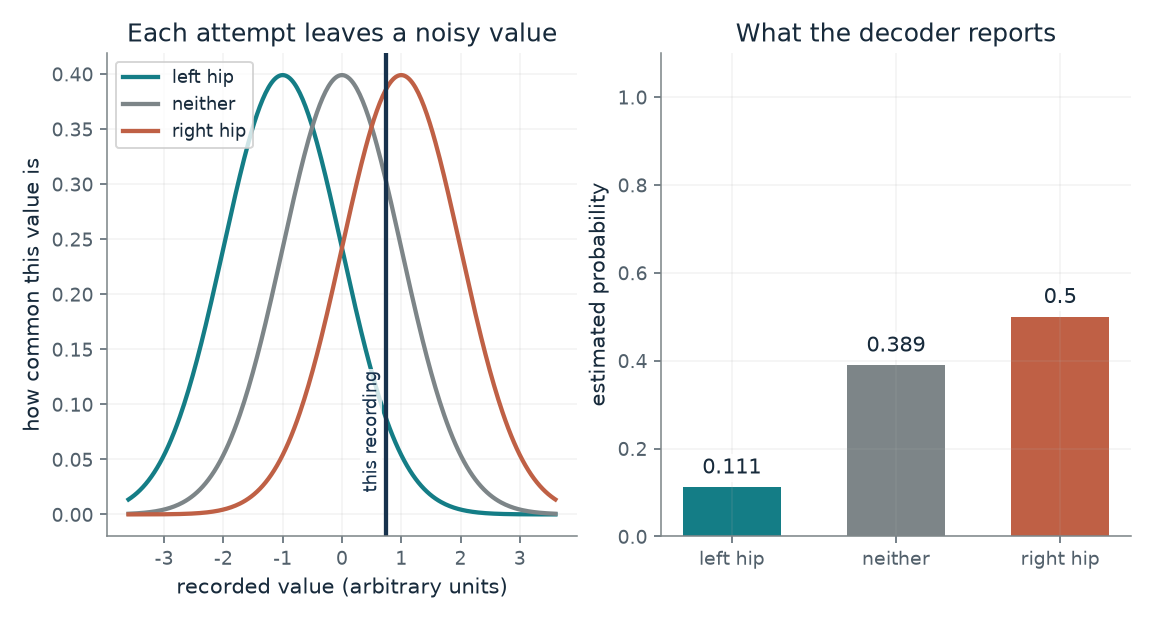

- **Probability of left hip:** 0.111
- **Probability of neither:** 0.389
- **Probability of right hip:** 0.5
- **Most likely attempt:** right hip

At recorded value 0.75 with noise 1, the most likely attempt is right hip at probability 0.5. The decoder gives a probability for each attempt and never a command.

Weights for left hip, neither, right hip: e^(-(0.75 - (-1))^2 / 2) = 0.216, e^(-(0.75 - (0))^2 / 2) = 0.755, e^(-(0.75 - (1))^2 / 2) = 0.969. Each probability is its weight divided by the total 1.94.

In [2]:
figure, values, explanation = decoder_picture(**{'x': 0.75, 'sigma': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a decoder turn a noisy recording into probabilities?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Recorded value = 0.5, Noise (sigma) = 1: At x = 0.5 the two attempts get exactly the same probability, 0.422 each, and the left hip gets 0.155. The decoder gives a graded estimate and not a command, and a tie is allowed.

**Takeaway:** A recording does not say 'move the left leg'. It supports probabilities, which the system then uses.

**Why it matters:** This is the first job mathematics does in the book: it turns messy measurements into an estimate that can guide an action.

**In brains and behavior:** The brain recordings were measurements associated with attempted movement; the chapter notes the paper says intention and attempt, not thought.

**In machines:** The decoder is a program that maps measurements to estimates; its probabilities helped set the strength of stimulation.

**Where it applies:** One recorded value, three attempts that start equally likely, and equal noise for each. A real decoder uses many measurements and learned weights.

**Check your understanding:** With noise 2 instead of 1, does a recording at 1 (the right-hip center) make the right hip more certain or less certain than with noise 1?

<details><summary>Show the answer</summary>

Less certain. Greater noise blurs the three bell curves together, so the right hip's probability falls (from about 0.574 to about 0.402 here) and the others rise.

</details>

*Source: Chapter 1, A recording is not a command. A constructed illustration of the chapter's statement that the decoder estimated the probabilities of attempting to flex the left hip, the right hip or neither. The bell-curve model, the centers and the noise are invented here; the study's decoder is built differently and uses several recording sites.*

## C01-D02: How much calibration data does a decoder need?

A decoder learns the typical recording for each attempt from examples. How does its accuracy depend on how many examples it saw, and how noisy the recordings are?

The decoder learns where each attempt typically lands by averaging the examples it saw. With few examples, those averages are off by about sigma over the square root of the number of examples, and misplaced centers cause avoidable mistakes. More examples shrink that error, but accuracy can never pass the ceiling set by the noise in single recordings.

$$
\text{spread of the learned center}=\frac{\sigma}{\sqrt{n}},\qquad \text{ceiling}=\frac{4\,\Phi\!\left(\tfrac{1}{2\sigma}\right)-1}{3}
$$

**Symbols:** n: calibration examples per attempt; sigma: noise in a single recording; Phi: the standard bell-curve cumulative probability; ceiling: the best accuracy a nearest-center rule can reach with the three centers known exactly

**Predict before looking:** At noise 1, predict whether 5 examples per attempt are enough to get near the ceiling, or whether you need many more.

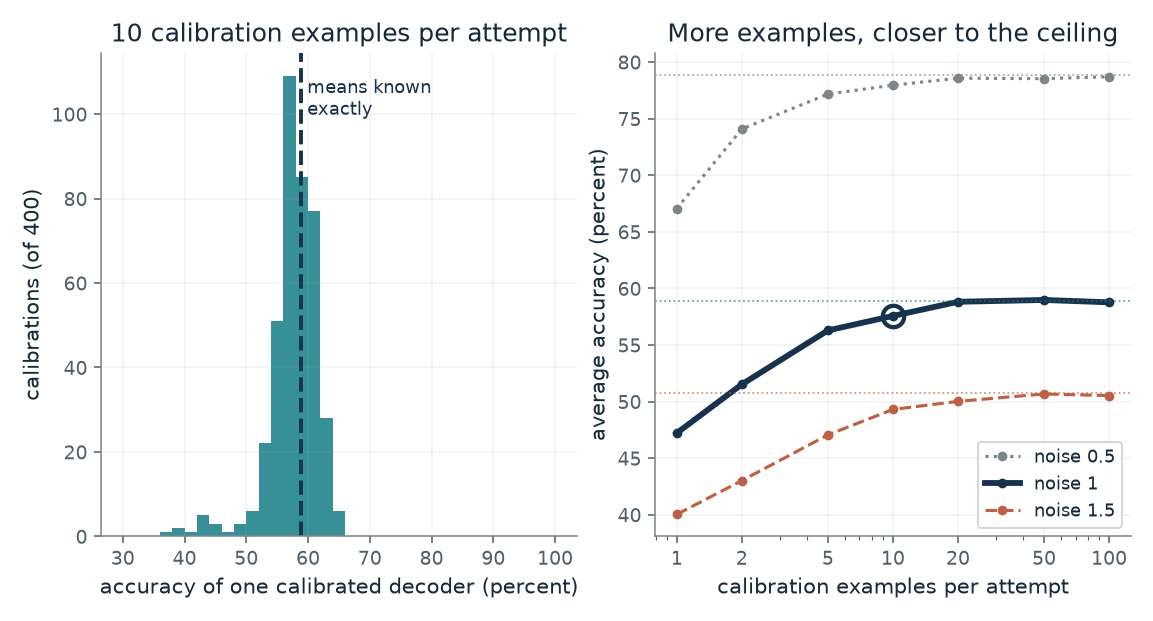

- **Average accuracy:** 57.6 percent
- **Accuracy if the means were known:** 58.9 percent
- **Gap to that ceiling:** 1.3 points
- **Worst tenth of calibrations:** 54 percent or less

With 10 examples per attempt and noise 1, 400 simulated calibrations averaged 57.6 percent correct, against a ceiling of 58.9 percent. The spread between calibrations is part of the answer: the worst tenth scored 54 percent or less.

Each calibration estimates a mean from 10 noisy examples, whose own error has spread 1 / sqrt(10) = 0.316. Ceiling: (4 x Phi(0.5 / 1) - 1) / 3 = 0.589, where Phi is the bell-curve cumulative probability.

In [3]:
figure, values, explanation = calibration_picture(**{'n': 10, 'sigma': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much calibration data does a decoder need?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Examples per attempt = 5, Noise (sigma) = 1: At noise 1, five examples per attempt averaged about 56 percent against a ceiling of about 59, and a few calibrations did much worse. One example per attempt averages about 47 percent, so the first few examples close most of the gap and later ones add little.

**Takeaway:** Calibration is estimation too: a few noisy examples give a noisy decoder, and the error in each learned center shrinks like one over the square root of the examples.

**Why it matters:** It shows why the study's time spent calibrating, and recalibrating on later days, is part of the mathematics and not just housekeeping.

**In brains and behavior:** The person supplied the examples by attempting each movement; the chapter says Oskam supplied the examples and the machine found the pattern.

**In machines:** The decoder estimates its own parameters from examples, and the examples it saw limit how well it can estimate.

**Where it applies:** A one-number recording, equal noise, centers at -1, 0 and 1, and a nearest-learned-center rule. The study's decoder was calibrated differently and updated over later days. A simulation here is not a measurement of any person or system.

**Check your understanding:** Why does halving the noise help more than quadrupling the examples?

<details><summary>Show the answer</summary>

The ceiling itself depends on the noise, and quadrupling the examples only halves the center error. Halving the noise both halves the center error and lifts the ceiling.

</details>

*Source: Chapter 1, A recording is not a command. Simulation with disclosed seeds: 400 calibrations per setting, each tested on 300 fresh recordings (100 per attempt), using the invented three-center model of C01-D01. It does not model the study's calibration, whose five-minute standing test and six weeks of preparation the chapter reports.*

## C01-D03: Why not give every voice an equal say?

A person and a machine estimate the same quantity and one is steadier. What does an equal share do to the error spread, and what does a reliability weight do?

The blend's spread depends on how much of each voice goes in. Putting all weight on the steadier source gives its own spread. Moving a small share to the weaker source lowers the spread, because their errors partly cancel, and the best share is the one in inverse proportion to each source's variance. An equal share goes too far when one source is much weaker.

$$
w^{*}=\frac{\sigma_m^{2}}{\sigma_p^{2}+\sigma_m^{2}},\qquad \sigma_{\text{blend}}^{2}=w^{2}\sigma_p^{2}+(1-w)^{2}\sigma_m^{2},\qquad \sigma_{*}^{2}=\frac{1}{1/\sigma_p^{2}+1/\sigma_m^{2}}
$$

**Symbols:** w: the share given to the person; the machine gets 1 minus w; sigma_p, sigma_m: the error spread of the person's and the machine's estimates; w*: the share that gives the smallest blend spread; sigma_*: the smallest achievable spread

**Predict before looking:** If the person is twice as variable as the machine, predict whether a plain 50-50 average beats the machine alone.

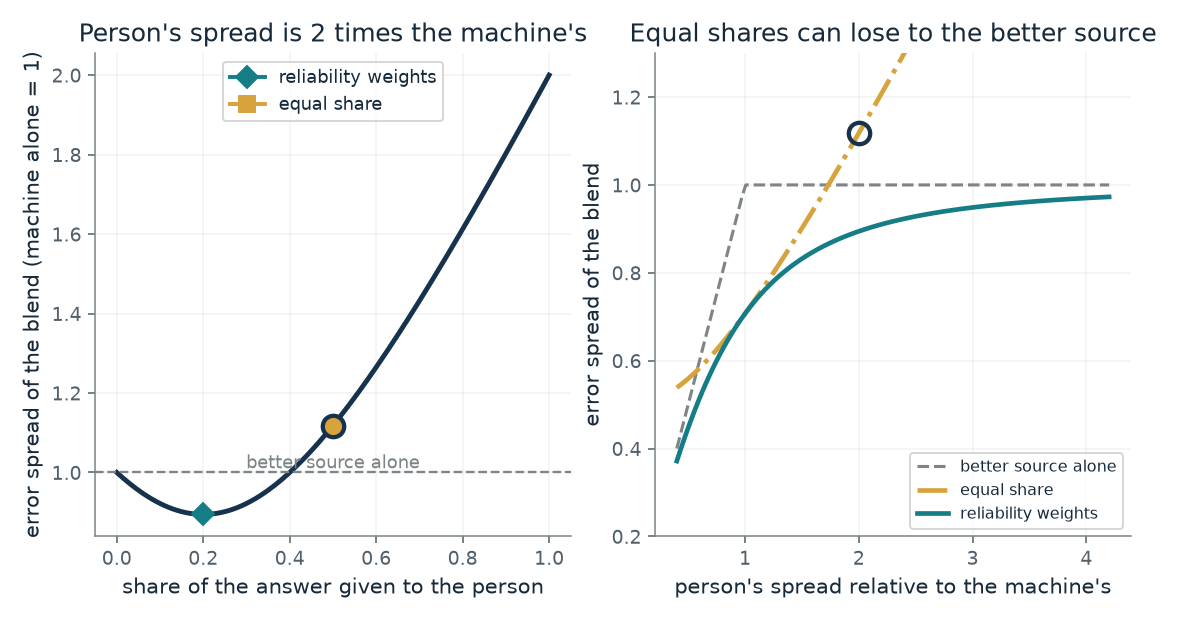

- **Blend error spread:** 1.12
- **Better source alone:** 1
- **Blend against the better source:** worse
- **Share given to the person:** 0.5

With the person 2 times as variable, an equal share gives a spread of 1.12, above the 1 of the better source alone. Mixing in a much weaker voice at equal weight hurts.

Blend spread = sqrt(w^2 x 2^2 + (1 - w)^2 x 1^2). Equal share w = 0.5 gives sqrt(1 + 0.25) = 1.12. Reliability weight w = 1 / (2^2 + 1) = 0.2 gives 0.894, which equals 1 / sqrt(1/2^2 + 1/1^2).

In [4]:
figure, values, explanation = weights_picture(**{'ratio': 2, 'rule': 'equal share'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why not give every voice an equal say?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Person's spread relative to the machine's = 2, Rule for the share = equal share: No. The equal share gives a spread of about 1.12 against the machine's 1. Reliability weights of 0.2 for the person and 0.8 for the machine give about 0.894, better than either source alone.

**Takeaway:** Under no bias and independent errors, a reliability weight beats either source alone, while an equal share can lose to the better one.

**Why it matters:** It turns the question 'should I trust the tool?' into a sharper one: how much weight does each source deserve, given how reliable it is?

**In brains and behavior:** The same rule was tested on how people combine sight and touch (C01-D05).

**In machines:** An engineer can use the rule to combine uncertain measurements, as the chapter says.

**Where it applies:** Both estimates are unbiased and their errors are independent. Shared errors or a consistent bias can change the answer. Spread means how much an estimate varies from one attempt to the next.

**Check your understanding:** With equal spreads, what is the best share for the person, and what is the blend's spread?

<details><summary>Show the answer</summary>

The best share is one half, and the spread is 1/sqrt(2), about 0.71 of either source alone, because with equal reliability the plain average is the reliability-weighted blend.

</details>

*Source: Chapter 1, Not every voice deserves an equal say. Book rule, stated in words in this chapter and worked in Chapter 2. The ratio of spreads is a control; the numbers are illustrative, not from a study. The rule needs the independence and no-bias conditions listed.*

## C01-D04: What did the partnership add?

A person scores 70 out of 100, a machine scores 80, and together they score 75. Did the machine help?

There are three differences to compute. The pair minus the person shows what the machine added to the person. The pair minus the machine shows what the person added to the machine. The pair minus the better of the two tells whether the partnership beat the best alternative that was available.

$$
\text{added}=S_{\text{pair}}-\max\bigl(S_{\text{person}},\,S_{\text{machine}}\bigr)
$$

**Symbols:** S_person: the person's solo score, 70 here; S_machine: the machine's solo score; S_pair: the score of the person and machine together; max: the better of the two solo scores

**Predict before looking:** With scores 70, 80 and 75, predict which of these is true: the pair beats the person; the pair beats the machine.

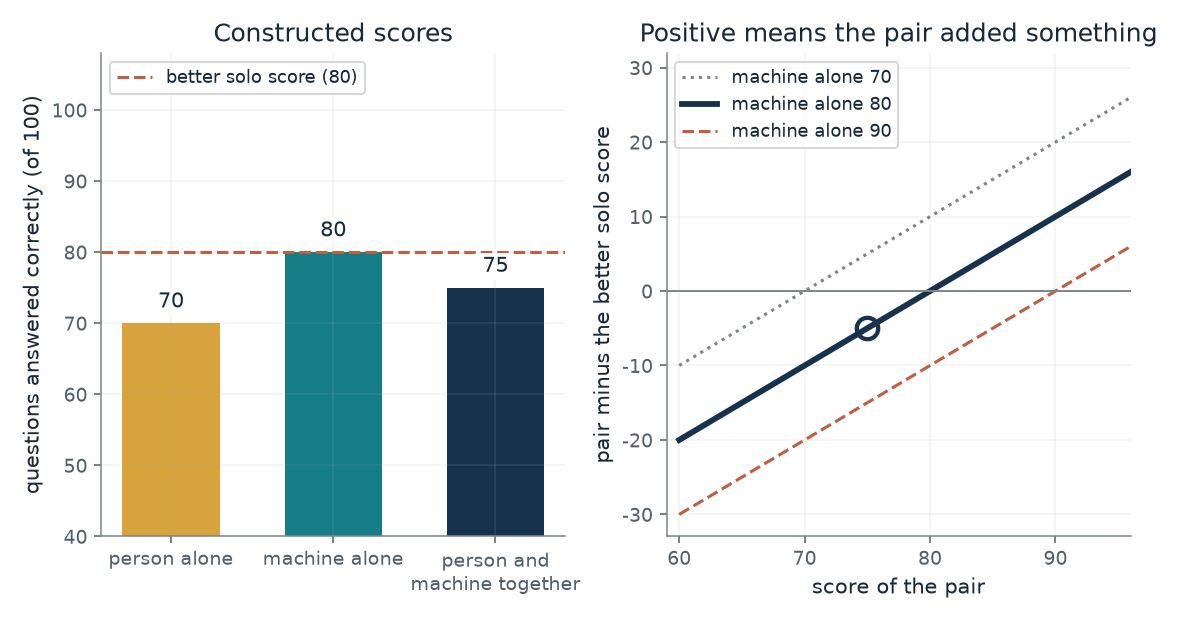

- **Pair minus person:** +5
- **Pair minus machine:** -5
- **Better solo score:** 80
- **Did the pair beat the best alone:** no, 5 short

The pair scores 75, which is +5 against the person and -5 against the machine. Saying only the first would hide that the better available result was 80.

Pair minus person = 75 - 70 = +5. Pair minus machine = 75 - 80 = -5. Pair minus the better solo score = 75 - 80 = -5.

In [5]:
figure, values, explanation = partnership_picture(**{'pair': 75, 'machine': 80})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What did the partnership add?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Pair's score = 75, Machine's solo score = 80: Both statements are true in different directions: the pair beats the person by 5 and loses to the machine by 5. Reporting only the first would hide the better available result.

**Takeaway:** Compare the pair with its best real alternative, not only with the weaker member.

**Why it matters:** The arithmetic turns 'did the machine help?' into a sharper question: what did the partnership add compared with the best alternative?

**In brains and behavior:** A person's solo score is a measured alternative only when the person could do the task alone.

**In machines:** A machine's solo score matters only if the machine could be deployed alone.

**Where it applies:** Both solo scores are real alternatives. A walking aid cannot walk alone as a person does, so comparing its solo score with a person's would answer nothing. The right comparison depends on the task and the outcome that matters. With only 100 questions a gap of a few points may be sampling noise, a point the chapter's invented numbers do not address.

**Check your understanding:** The pair scores 85 and the machine 80. What do the three comparisons say, and what does the result hint at?

<details><summary>Show the answer</summary>

Pair minus person is +15, pair minus machine is +5, and pair minus the best solo score is +5. The pair beat the best alternative, which would point to a real contribution from the partnership, subject to sampling noise.

</details>

*Source: Chapter 1, Not every voice deserves an equal say. The chapter's constructed example, stated as invented numbers and not a study's results. The machine's score and the pair's score are controls here.*

## C01-D05: How does a prediction tell two rules apart?

Sight and touch both judge a bar's height, and the picture can be made grainier. What does each combination rule predict about leaning toward touch, and about how finely the two senses together discriminate?

The reliability-weight rule makes two predictions. As the picture gets grainier, the judgment should lean smoothly toward touch. And the two senses together should discriminate more finely than either alone. A plain average predicts no lean. A winner-take-all rule predicts a sudden jump and no combined gain. Observing a lean and a gain together fits the reliability rule and counts against the others.

$$
w_{\text{touch}}=\frac{1/\sigma_h^{2}}{1/\sigma_h^{2}+1/\sigma_v^{2}},\qquad \sigma_{\text{both}}^{2}=\frac{\sigma_v^{2}\sigma_h^{2}}{\sigma_v^{2}+\sigma_h^{2}}
$$

**Symbols:** sigma_v, sigma_h: the spread of the visual and the touch judgments; w_touch: the share of the judgment given to touch; sigma_both: the predicted spread when both senses are used

**Predict before looking:** If vision becomes twice as variable as touch, predict how much of the judgment each rule gives to touch, and which rule predicts a gain over the steadier sense.

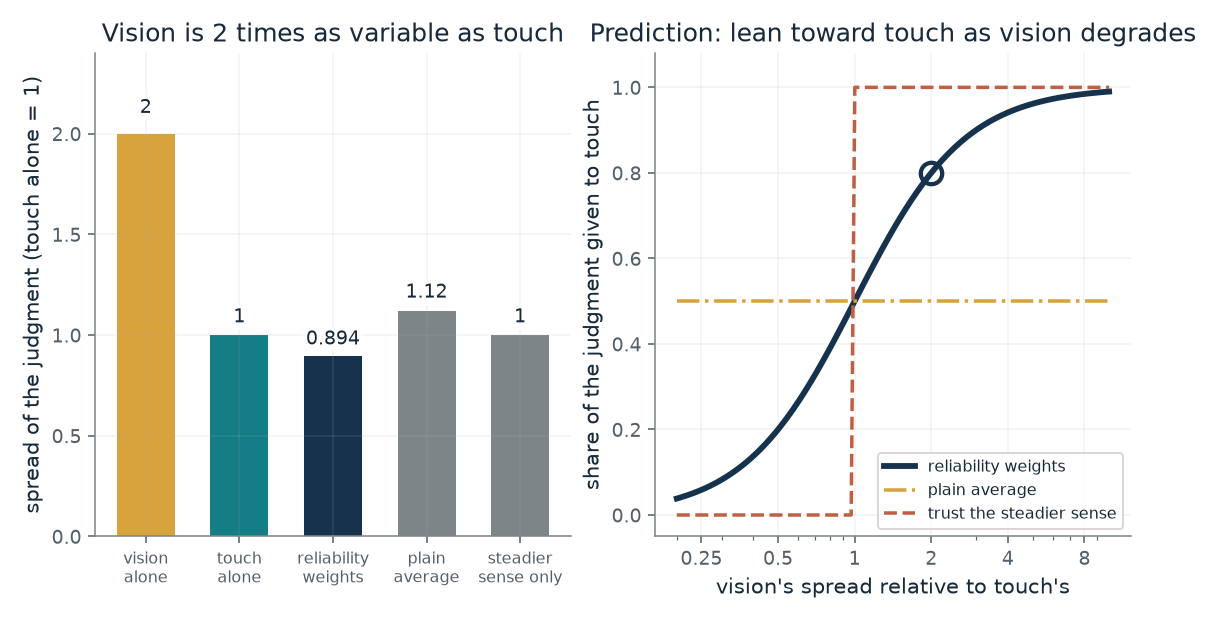

- **Share given to touch:** 0.8
- **Spread of the combined judgment:** 0.894
- **Steadier sense alone:** 1
- **Combined against the steadier sense:** better

Reliability weights give touch 0.8 here, and the combined spread 0.894 is better than the steadier sense alone (1). The lean grows smoothly as the picture gets grainier.

Touch spread 1, vision spread 2. Reliability weight on touch = 2^2 / (2^2 + 1) = 0.8. For the selected rule the share is 0.8, so spread = sqrt(0.8^2 x 1 + 0.2^2 x 2^2) = 0.894.

In [6]:
figure, values, explanation = rules_picture(**{'ratio': 2, 'rule': 'reliability weights'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a prediction tell two rules apart?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Vision's spread relative to touch's = 2, Combination rule = reliability weights: Reliability weights give touch 0.8 and predict a combined spread of 0.894, finer than either sense (1 and 2). A plain average gives touch 0.5 whatever the picture quality, and always trusting the steadier sense can never beat it.

**Takeaway:** A rule is an idea until its predictions are checked, and different rules predict different leans and different gains.

**Why it matters:** This is the difference between describing, predicting and building: the rule described a pattern, predicted what happens when a sense degrades, and can be used to build a machine that combines measurements.

**In brains and behavior:** A match to behavior does not prove the brain does this arithmetic; the paper offers neural populations as a candidate and tests none.

**In machines:** The same formula specifies a computation a machine performs on uncertain measurements.

**Where it applies:** The three rules shown are hypotheses for contrast. Unbiased judgments and independent errors are assumed. The chapter notes a close match is good evidence about behavior, and how neurons produce it takes more evidence.

**Check your understanding:** If people showed a smooth lean toward touch but no gain from using both senses, which of the three rules would that count against?

<details><summary>Show the answer</summary>

It would count against the reliability-weight rule, which predicts both. The plain average predicts no lean, and the steadier-sense rule predicts a jump, so neither would fit a smooth lean either.

</details>

*Source: Chapter 1, The rule was tested on people. The chapter reports Ernst and Banks (2002): judgments came close to the predicted lean toward touch as the picture grew grainier and to the prediction that two senses discriminate more finely than either alone. The numbers plotted here are constructed from the rule and are not their measurements.*

## Bring it to your own question

Ask what each source reports and how reliable it is, whether their errors are independent, what the best real alternative is, and whether a claim is a measured result, a drawn comparison or an open question. Work the weights and the comparison by hand before running any simulation, and say what was constructed.

Use the `mmi-ch01-making-mind` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.